# Aureas walkthrough

This notebook runs the Python version of Aureas on a folder of recordings:

1. The pipeline step by step on one recording: spectrogram, denoising, segmentation, features and LAMDA.
2. The full exploration of the folder and the results CSV (same columns as the MATLAB Excel).
3. The clusters: summary, representative elements, members and audio.
4. The effect of the dominant-frequency correction.
5. (Optional) Comparison with a CSV/Excel produced by the MATLAB application.

Set the paths in the next cell and run everything. A handful of recordings is enough.

In [9]:
import os, sys
from pathlib import Path
# --- Paths ----------------------------------------------------------------------
AUDIO_DIR = Path(os.environ.get("AUREAS_AUDIO_DIR", r"C:\Users\Lucas\Documents\UdeA\2026_MagMed\SNR_Selection\10RecordingSample"))      # searched recursively
RESULTS_DIR = Path(os.environ.get("AUREAS_RESULTS_DIR", r"C:\Users\Lucas\Documents\UdeA\2026_MagMed\SNR_Selection\10RecordingSample\Results"))               # a new run folder is created inside
AUREAS_PY = Path(os.environ.get("AUREAS_PY", r"C:\Users\Lucas\Aureas-v1-2026"))

In [10]:
if (AUREAS_PY / "aureas").exists() and str(AUREAS_PY.resolve()) not in sys.path:
    sys.path.insert(0, str(AUREAS_PY.resolve()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import Audio, display

import aureas
from aureas.io import list_audio, load_audio
from aureas.matlab_compat import spectrogram

pd.set_option("display.max_columns", 30)
print("aureas", aureas.__version__)
files = list_audio(AUDIO_DIR)
print(f"{len(files)} recordings:", *[f.name for f in files[:20]], sep="\n  ")

aureas 0.1.0
10 recordings:
  1agazus_20250530_144700.wav
  1agazus_20250530_151600.wav
  1as_20250629_162900.wav
  1as_20250629_165900.wav
  1g_20250721_175400.wav
  1g_20250721_185400.wav
  angrab14_20250218_232100.wav
  angrab14_20250218_232400.wav
  angrab2h_20250218_181300.wav
  angrab2h_20250218_181600.wav


## 1. The pipeline step by step on one recording

Each stage is an independent function:

`spectrogram` → `denoise` → `detect_events` → `extract_features` → `MinMaxScaler` → `LAMDA`

1g_20250721_175400.wav: 60.0 s at 48000 Hz


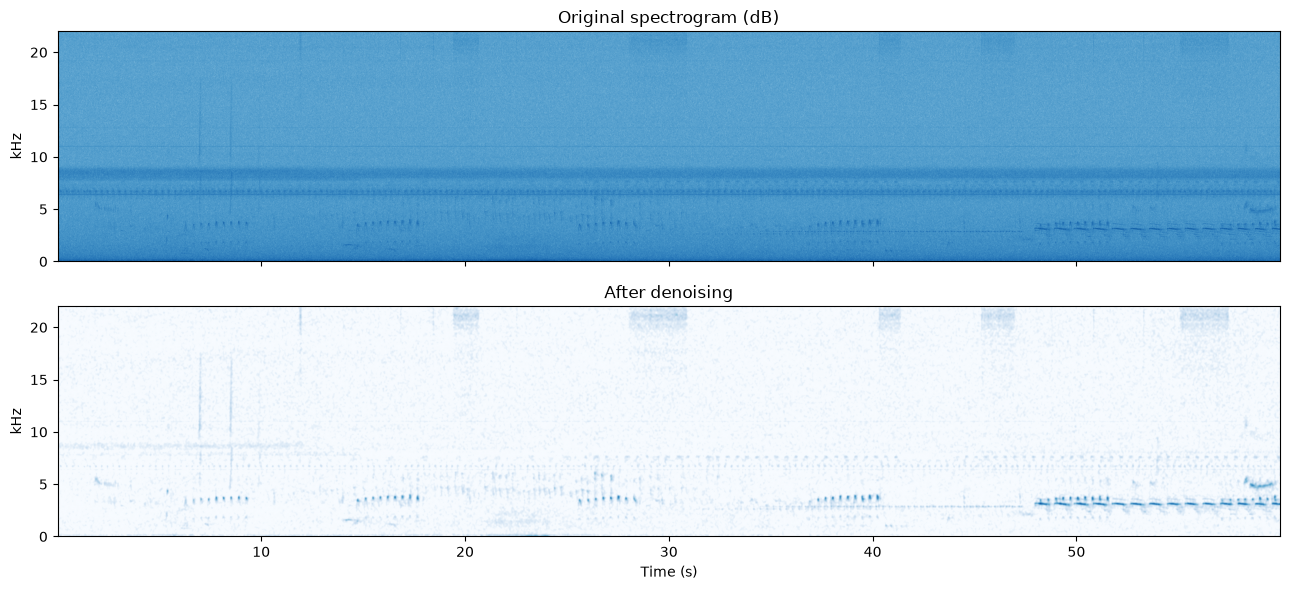

In [12]:
wav = files[4]
x, fs = load_audio(wav, channel=1)
print(f"{wav.name}: {len(x)/fs:.1f} s at {fs} Hz")

# Spectrogram with the MATLAB parameters: Hamming 1024, 50 % overlap, nfft 2048
S, f, t, P = spectrogram(x, fs, nwin=1024, noverlap=512, nfft=2048)

# Denoising: dB -> Gaussian filter (sigma 3) -> subtraction of the per-band mode
I = aureas.denoise(P, smooth_span=11)

fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
ax[0].imshow(10*np.log10(P[1:1025] + 1e-20), origin="lower", aspect="auto", cmap="Blues",
             extent=[t[0], t[-1], f[1]/1000, f[1024]/1000])
ax[0].set_title("Original spectrogram (dB)"); ax[0].set_ylabel("kHz")
ax[1].imshow(I, origin="lower", aspect="auto", cmap="Blues", extent=[t[0], t[-1], f[1]/1000, f[1024]/1000])
ax[1].set_title("After denoising"); ax[1].set_ylabel("kHz"); ax[1].set_xlabel("Time (s)")
for a in ax: a.set_ylim(0, 22)
plt.tight_layout(); plt.show()

angrab2h_20250218_201600.wav: 60.0 s at 48000 Hz


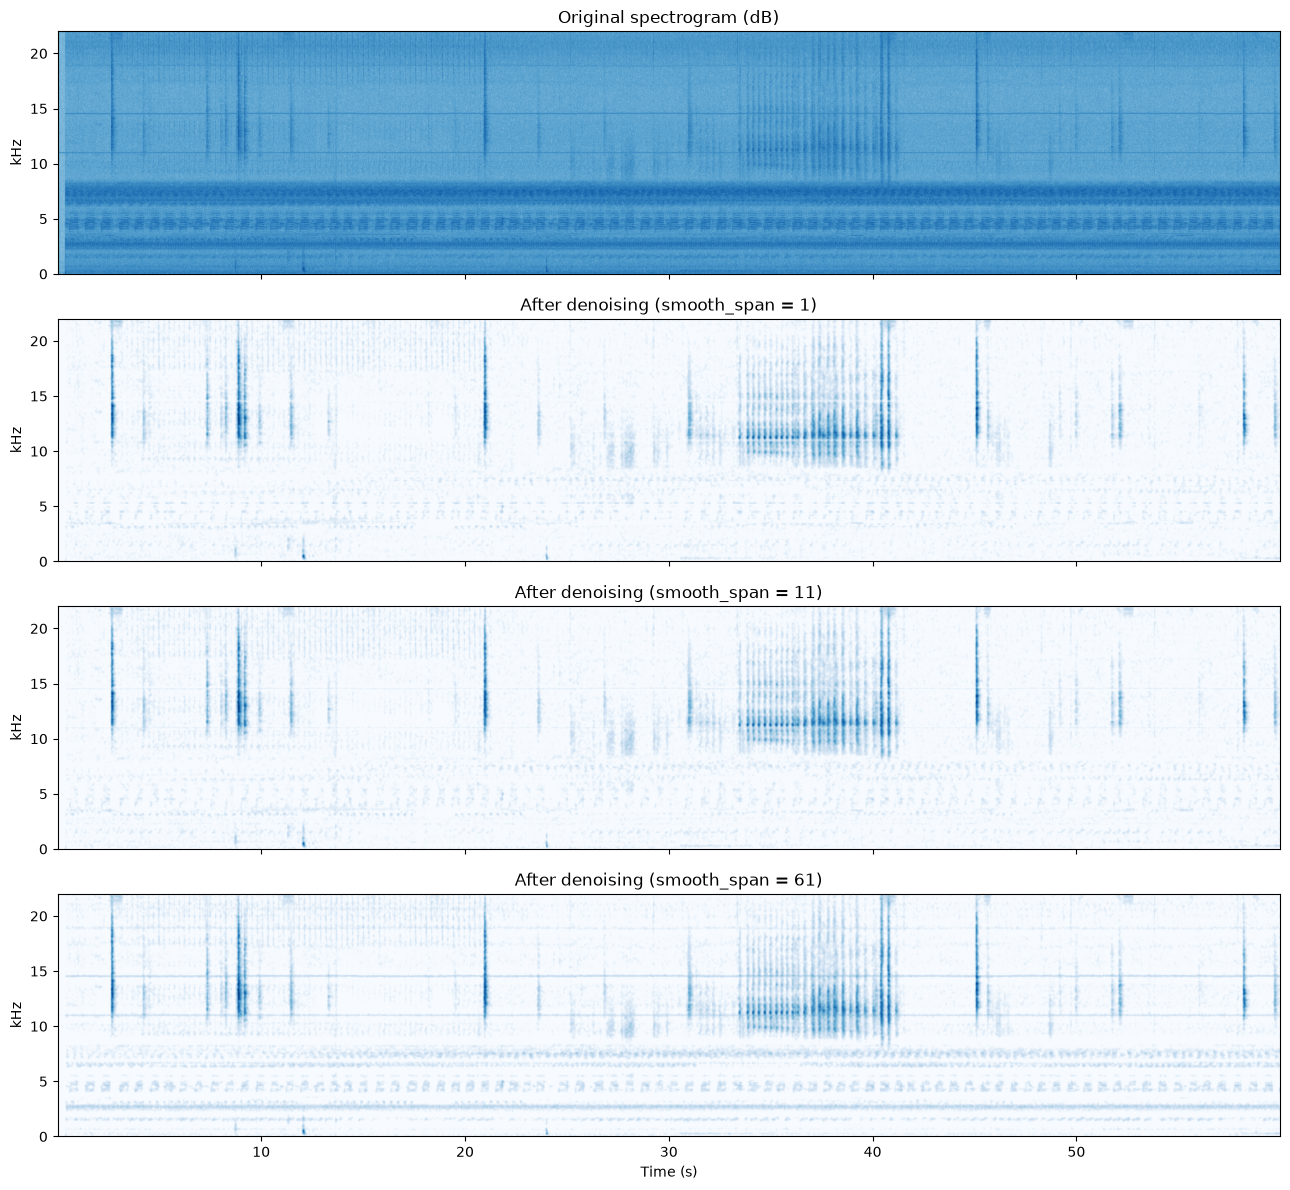

In [29]:
wav = files[456]
x, fs = load_audio(wav, channel=1)
print(f"{wav.name}: {len(x)/fs:.1f} s at {fs} Hz")

# Spectrogram with the MATLAB parameters: Hamming 1024, 50 % overlap, nfft 2048
S, f, t, P = spectrogram(x, fs, nwin=1024, noverlap=512, nfft=2048)

# Three smooth_span values to compare
spans = [1, 11, 61]
denoised = {s: aureas.denoise(P, smooth_span=s) for s in spans}

extent = [t[0], t[-1], f[1]/1000, f[1024]/1000]

# Shared color scale across the denoised panels so differences are real, not an artifact of autoscaling
vmin = min(I.min() for I in denoised.values())
vmax = max(I.max() for I in denoised.values())

fig, ax = plt.subplots(4, 1, figsize=(13, 12), sharex=True, sharey=True)

# Original
ax[0].imshow(10*np.log10(P[1:1025] + 1e-20), origin="lower", aspect="auto",
             cmap="Blues", extent=extent)
ax[0].set_title("Original spectrogram (dB)")

# Denoised versions
for a, s in zip(ax[1:], spans):
    a.imshow(denoised[s], origin="lower", aspect="auto", cmap="Blues",
             extent=extent, vmin=vmin, vmax=vmax)
    a.set_title(f"After denoising (smooth_span = {s})")

for a in ax:
    a.set_ylabel("kHz")
    a.set_ylim(0, 22)
ax[-1].set_xlabel("Time (s)")

plt.tight_layout(); plt.show()

137 events detected


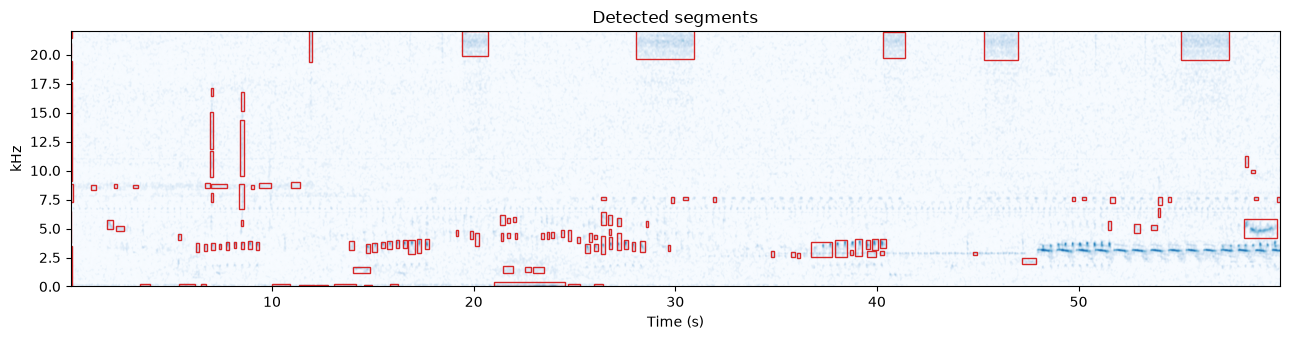

In [13]:
# Segmentation: Otsu x1.1 + opening 9x7 + closing 6x6 + geometric filters
events = aureas.detect_events(I, f, t)
print(f"{len(events)} events detected")

fig, ax = plt.subplots(figsize=(13, 3.5))
ax.imshow(I, origin="lower", aspect="auto", cmap="Blues", extent=[t[0], t[-1], f[1]/1000, f[1024]/1000])
for e in events.itertuples():
    ax.add_patch(Rectangle((e.t_start, e.f_low/1000), e.t_end-e.t_start, (e.f_high-e.f_low)/1000,
                           fill=False, ec="#d62728", lw=1))
ax.set_ylim(0, 22); ax.set_xlabel("Time (s)"); ax.set_ylabel("kHz"); ax.set_title("Detected segments")
plt.tight_layout(); plt.show()

In [14]:
# Features: Fdom, Fmin, Fmax + 23 coefficients (4x4 LFCC without c0, delta and delta-delta)
table, X, n_dropped = aureas.extract_features(S, f, t, fs, events)
print(f"{len(table)} segments with features, {n_dropped} dropped (too short or narrow for the LFCC)")
print("Feature matrix:", X.shape)
pd.DataFrame(X[:5], columns=aureas.feature_names()).round(3)

121 segments with features, 16 dropped (too short or narrow for the LFCC)
Feature matrix: (121, 26)


,fdom,fmin,fmax,lfcc_c1_t0,lfcc_c2_t0,lfcc_c3_t0,lfcc_c0_t1,lfcc_c1_t1,lfcc_c2_t1,lfcc_c3_t1,lfcc_c0_t2,lfcc_c1_t2,lfcc_c2_t2,lfcc_c3_t2,lfcc_c0_t3,lfcc_c1_t3,lfcc_c2_t3,lfcc_c3_t3,d_c0,d_c1,d_c2,d_c3,dd_c0,dd_c1,dd_c2,dd_c3
0,22289.062,21445.312,22992.188,-1.249,-1.859,-0.308,-47.565,-0.310,-0.126,-0.266,-48.132,0.388,1.109,1.426,-46.164,0.347,-2.534,0.871,-10.766,0.532,-0.225,0.393,17.834,-0.490,-2.688,-0.298
1,20414.062,19687.500,21023.438,1.315,-2.021,0.362,-45.094,-0.348,-0.184,0.462,-49.057,-0.807,-1.292,-0.353,-50.887,0.316,-0.470,1.159,-12.409,-0.333,0.517,0.266,14.801,1.393,-0.507,0.706
2,18632.812,17906.250,19429.688,-1.266,-1.861,-0.270,-47.871,-0.827,-0.230,0.327,-46.069,0.281,-0.935,0.303,-48.627,0.672,0.784,1.146,-11.604,0.646,0.882,0.472,15.749,-0.024,0.044,0.123
3,9632.812,9070.312,17648.438,-0.891,0.259,0.217,-34.555,-0.766,-0.065,-0.241,-36.674,-0.074,-0.073,0.102,-37.000,-0.088,0.269,-0.274,-11.501,0.268,0.003,-0.164,15.866,-0.069,0.333,0.040
4,8085.938,7265.625,8812.500,-1.768,-1.875,-0.355,-27.417,3.970,-1.894,-0.177,-25.506,3.739,-1.034,0.263,-26.562,3.267,-1.885,0.686,-6.473,1.678,-0.003,0.347,9.610,-3.105,-0.417,0.122


In [15]:
# Min-max scaling to [0, 1] and LAMDA 3pi, on this recording only
Z = aureas.MinMaxScaler().fit_transform(X)
labels, G, prototypes = aureas.LAMDA(nic_init="mean").fit_predict(Z)
print(f"{labels.max()} clusters + NIC; segments per class (0 = NIC):")
print(pd.Series(labels).value_counts().sort_index().to_dict())

20 clusters + NIC; segments per class (0 = NIC):
{0: 5, 1: 5, 2: 7, 3: 13, 4: 10, 5: 5, 6: 10, 7: 8, 8: 6, 9: 16, 10: 7, 11: 5, 12: 3, 13: 3, 14: 2, 15: 5, 16: 2, 17: 2, 18: 2, 19: 4, 20: 1}


## 2. Full exploration of the folder

`aureas.explore` does all of the above for every recording and saves a run folder with:

- `Classification_<date>.csv`: **the same columns as the MATLAB Excel** (File … Class, Membership) plus extra columns.
- `Full_results.csv`, `Normalized_features.csv`, `Memberships.csv`, `Run_summary.csv`.
- `clusters.csv`, `arrays.npz`, `config.yaml`, `run.yaml`.

In [16]:
res = aureas.explore(AUDIO_DIR, results_dir=RESULTS_DIR)
m = res.meta
print(f"{m['n_segments']} segments from {m['n_files']} recordings -> {m['n_clusters']} clusters + NIC "
      f"({m['n_dropped']} dropped). CV index: {m['cv_index']:.3f}")
print("Results in:", res.path)
res.table().head(10)

1526 segments from 10 recordings -> 36 clusters + NIC (82 dropped). CV index: 0.008
Results in: C:\Users\Lucas\Documents\UdeA\2026_MagMed\SNR_Selection\10RecordingSample\Results\2026-10-21_08-08-37_explore_10RecordingSample


,File,Month,Day,Hour,Minute,Start,End,Length,Fdom,FminVoc,FmaxVoc,Fmin,Fmax,Class,Membership,SegmentID,Year,Second,Datetime,Site,Path,SampleRate,MembershipAssigned,IsRepresentative
0,1agazus_20250530_144700.wav,5,30,14,47,0.010667,0.330667,0.320000,23132.8125,22265.6250,23953.1250,23.4375,24000.0,1,0.996906,0,2025,0,2025-05-30 14:47:00,1agazus,C:\Users\Lucas\Documents\UdeA\2026_MagMed\SNR_...,48000,0.217662,True
1,1agazus_20250530_144700.wav,5,30,14,47,0.010667,0.480000,0.469333,8414.0625,8414.0625,22054.6875,23.4375,24000.0,1,0.543056,1,2025,0,2025-05-30 14:47:00,1agazus,C:\Users\Lucas\Documents\UdeA\2026_MagMed\SNR_...,48000,0.435587,False
2,1agazus_20250530_144700.wav,5,30,14,47,0.010667,0.469333,0.458667,23.4375,23.4375,7898.4375,23.4375,24000.0,3,1.000000,2,2025,0,2025-05-30 14:47:00,1agazus,C:\Users\Lucas\Documents\UdeA\2026_MagMed\SNR_...,48000,1.000000,False
3,1agazus_20250530_144700.wav,5,30,14,47,0.597333,0.842667,0.245333,796.8750,796.8750,3070.3125,23.4375,24000.0,4,0.996424,3,2025,0,2025-05-30 14:47:00,1agazus,C:\Users\Lucas\Documents\UdeA\2026_MagMed\SNR_...,48000,0.996424,False
4,1agazus_20250530_144700.wav,5,30,14,47,0.960000,1.194667,0.234667,7734.3750,6867.1875,7757.8125,23.4375,24000.0,5,0.883558,4,2025,0,2025-05-30 14:47:00,1agazus,C:\Users\Lucas\Documents\UdeA\2026_MagMed\SNR_...,48000,0.883558,False
5,1agazus_20250530_144700.wav,5,30,14,47,0.970667,1.141333,0.170667,726.5625,703.1250,5437.5000,23.4375,24000.0,4,0.994084,5,2025,0,2025-05-30 14:47:00,1agazus,C:\Users\Lucas\Documents\UdeA\2026_MagMed\SNR_...,48000,0.994084,False
6,1agazus_20250530_144700.wav,5,30,14,47,0.992000,1.098667,0.106667,9164.0625,9164.0625,9703.1250,23.4375,24000.0,5,0.937649,6,2025,0,2025-05-30 14:47:00,1agazus,C:\Users\Lucas\Documents\UdeA\2026_MagMed\SNR_...,48000,0.937649,False
7,1agazus_20250530_144700.wav,5,30,14,47,1.290667,1.429333,0.138667,726.5625,726.5625,4125.0000,23.4375,24000.0,4,0.995563,7,2025,0,2025-05-30 14:47:00,1agazus,C:\Users\Lucas\Documents\UdeA\2026_MagMed\SNR_...,48000,0.995563,False
8,1agazus_20250530_144700.wav,5,30,14,47,1.301333,1.408000,0.106667,4593.7500,4359.3750,5367.1875,23.4375,24000.0,19,0.939094,8,2025,0,2025-05-30 14:47:00,1agazus,C:\Users\Lucas\Documents\UdeA\2026_MagMed\SNR_...,48000,0.939094,False
9,1agazus_20250530_144700.wav,5,30,14,47,1.472000,1.781333,0.309333,7757.8125,6937.5000,7757.8125,23.4375,24000.0,5,0.882703,9,2025,0,2025-05-30 14:47:00,1agazus,C:\Users\Lucas\Documents\UdeA\2026_MagMed\SNR_...,48000,0.882703,False


In [8]:
# Summary per cluster (Class 1 = NIC, as in MATLAB)
cols = ["Class", "n_segments", "pct_of_all", "confident_pct", "membership_median",
        "fdom_median", "fmin_median", "fmax_median", "length_median", "n_recordings", "closest_class"]
res.clusters[cols].sort_values("n_segments", ascending=False).round(2).head(15)

,Class,n_segments,pct_of_all,confident_pct,membership_median,fdom_median,fmin_median,fmax_median,length_median,n_recordings,closest_class
0,1,20492,31.14,0.00,0.60,11742.19,10359.38,13031.25,0.20,427,159
19,20,5218,7.93,79.86,0.95,20601.56,20109.38,21187.50,0.15,327,5
1,2,4099,6.23,100.00,1.00,23203.12,22195.31,24000.00,0.45,376,13
2,3,3850,5.85,100.00,1.00,445.31,304.69,1617.19,0.19,328,152
4,5,2005,3.05,71.52,0.92,18539.06,18140.62,18820.31,0.13,267,76
14,15,1953,2.97,99.54,0.98,2109.38,1687.50,2507.81,0.16,255,7
22,23,1330,2.02,58.80,0.91,7242.19,6867.19,7429.69,0.18,60,56
5,6,1161,1.76,18.69,0.86,7570.31,7523.44,8015.62,0.33,62,56
7,8,1139,1.73,85.43,0.93,4875.00,4710.94,5367.19,0.14,138,64
29,30,1129,1.72,65.72,0.91,3820.31,3398.44,4265.62,0.54,137,25


## 3. Clusters: representative elements and members

The representative element of a cluster is the member with the highest global adequacy degree (GAD), as in `Metodologia.m`.

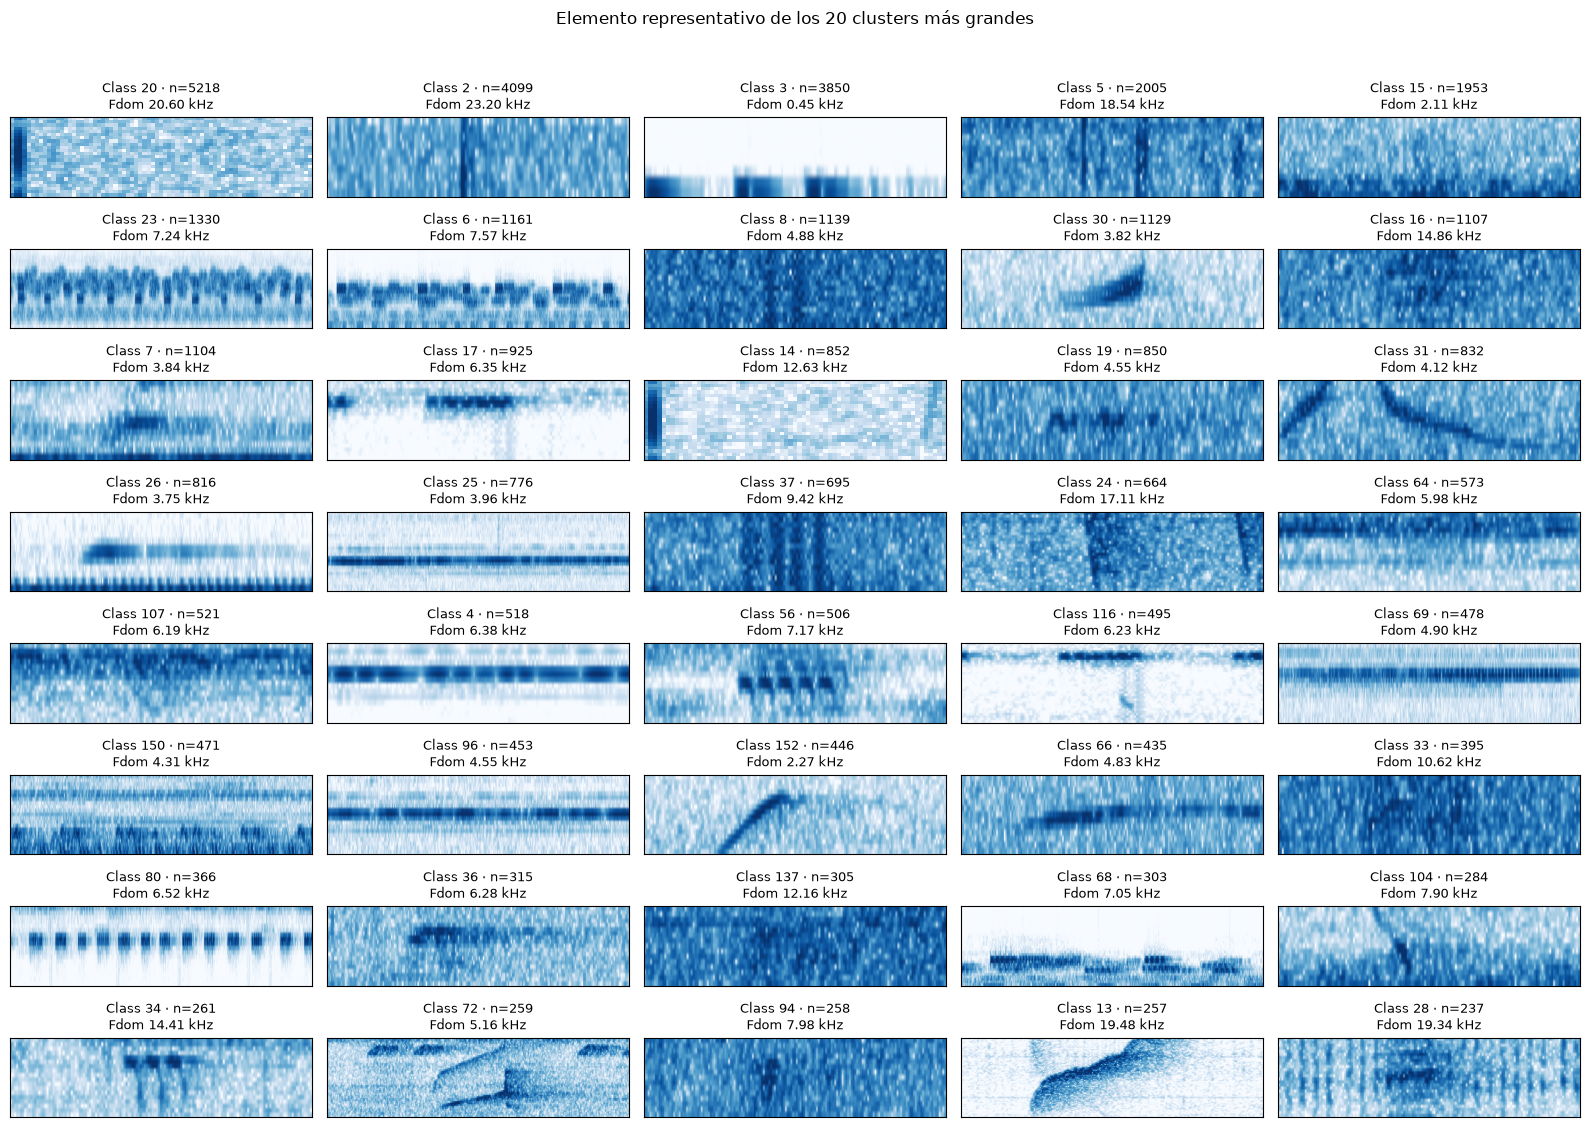

In [9]:
def plot_segment(ax, row, ctx=0.15, fpad=400, title=None):
    a, b = max(0, row.Start - ctx), row.End + ctx
    y, sr = load_audio(row.Path, 1, a, b)
    nwin = 512
    S_, f_, t_, P_ = spectrogram(y, sr, nwin, 384, nwin)
    lo, hi = max(0, row.FminVoc - fpad), min(sr/2, row.FmaxVoc + fpad)
    r = (f_ >= lo) & (f_ <= hi)
    img = 10*np.log10(P_[r] + 1e-20); vmax = np.percentile(img, 99.5)
    ax.imshow(img, origin="lower", aspect="auto", cmap="Blues", vmin=vmax-45, vmax=vmax,
              extent=[a, a + len(y)/sr, lo/1000, hi/1000])
    ax.set_xticks([]); ax.set_yticks([])
    if title: ax.set_title(title, fontsize=9)

seg = res.segments
top = res.clusters[res.clusters.Class > 1].sort_values("n_segments", ascending=False).head(40)
fig, axes = plt.subplots(8, 5, figsize=(16, 11))
for ax, c in zip(axes.ravel(), top.itertuples()):
    r = seg.loc[int(c.representative)]
    plot_segment(ax, r, title=f"Class {c.Class} · n={c.n_segments}\nFdom {c.fdom_median/1000:.2f} kHz")
fig.suptitle("Elemento representativo de los 20 clusters más grandes", y=1.02)
plt.tight_layout(); plt.show()

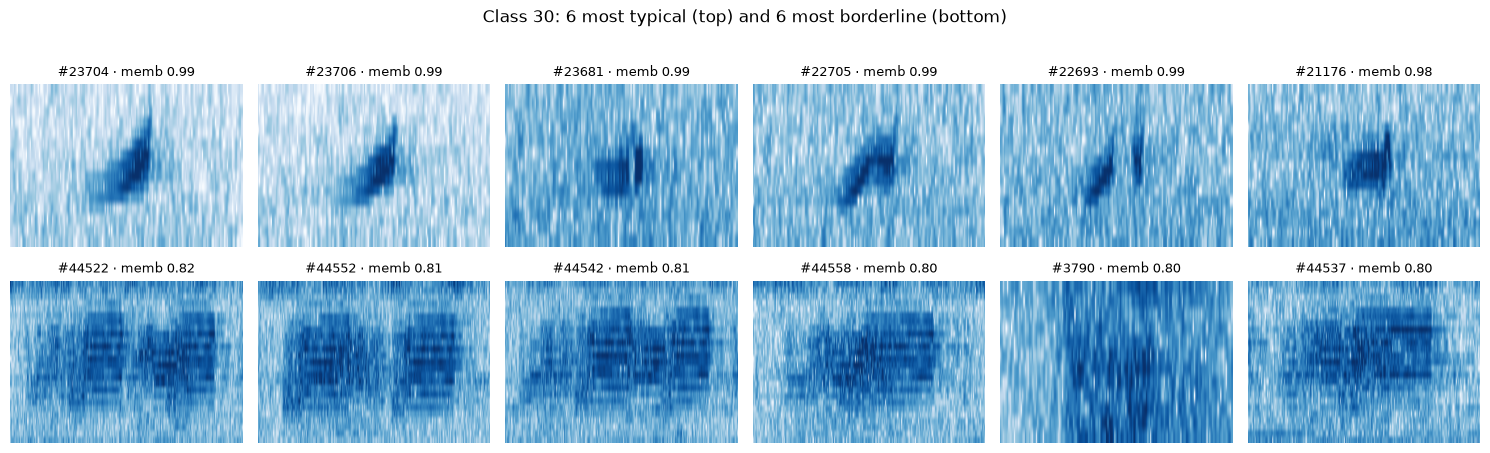

In [11]:
# Members of one cluster, from most typical to most borderline (change CLASS to see another one)
CLASS = 30
mem = res.members(CLASS, "typical")
sel = pd.concat([mem.head(6), mem.tail(6)])
fig, axes = plt.subplots(2, 6, figsize=(15, 4.4))
for ax in axes.ravel(): ax.set_axis_off()
for ax, r in zip(axes.ravel(), sel.itertuples()):
    plot_segment(ax, r, title=f"#{r.SegmentID} · memb {r.MembershipAssigned:.2f}")
fig.suptitle(f"Class {CLASS}: 6 most typical (top) and 6 most borderline (bottom)", y=1.02)
plt.tight_layout(); plt.show()

In [12]:
# Listen to the representative element of that cluster (0.5 s before and after)
r = seg.loc[int(res.clusters.set_index("Class").loc[CLASS, "representative"])]
y, sr = load_audio(r.Path, 1, max(0, r.Start - 0.5), r.End + 0.5)
print(f"{r.File}  {r.Start:.2f}-{r.End:.2f} s  Fdom {r.Fdom:.0f} Hz")
display(Audio(y, rate=sr))

1ghippo2_20250722_030800.wav  18.74-18.92 s  Fdom 1359 Hz


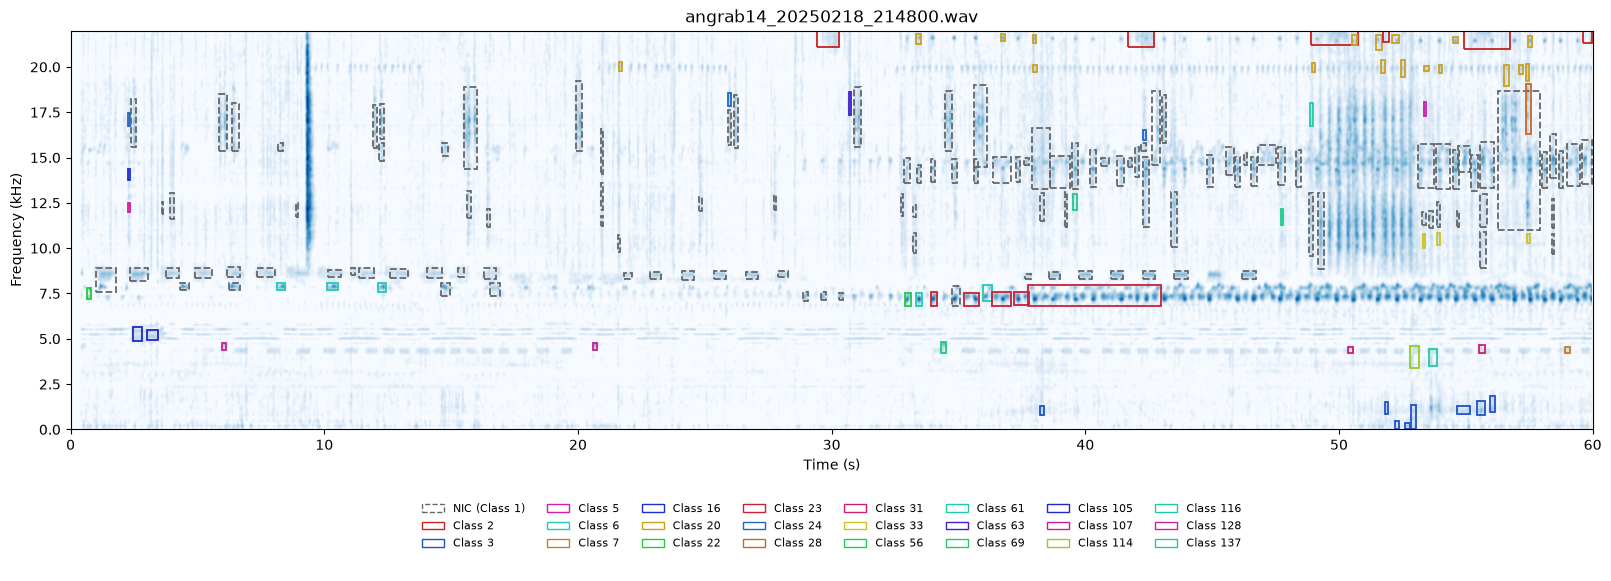

In [13]:
from matplotlib.colors import hsv_to_rgb
from matplotlib.patches import Patch

def plot_segmentos_por_clase(res, archivo, mostrar_numeros=False):
    archivo = Path(archivo).resolve()
    rutas = res.segments["Path"].map(lambda p: str(Path(p).resolve()))
    segmentos_audio = res.segments.loc[rutas == str(archivo)]
    if segmentos_audio.empty:
        raise ValueError(f"No hay segmentos clasificados de {archivo.name} en esta corrida.")

    
    sp, dn = res.config["spectrogram"], res.config["denoising"]
    audio, sr = load_audio(archivo, channel=res.config["channel"])
    _, frecuencias, tiempos, potencia = spectrogram(
        audio, sr, nwin=sp["nwin"], noverlap=sp["noverlap"], nfft=sp["nfft"])
    imagen = aureas.denoise(potencia, nwin=sp["nwin"],
                           sigma=dn["gaussian_sigma"], smooth_span=dn["mode_smooth_span"])

    
    clases = sorted(int(c) for c in segmentos_audio["Class"].unique())
    colores = {
        c: ("#666666" if c == 1 else hsv_to_rgb([((c - 2) * 0.61803398875) % 1, 0.85, 0.80]))
        for c in clases
    }
    ncols = min(8, len(clases))
    filas_leyenda = int(np.ceil(len(clases) / ncols))
    fig = plt.figure(figsize=(16, 4.8 + 0.3 * filas_leyenda), layout="constrained")
    grid = fig.add_gridspec(2, 1, height_ratios=[4, max(0.4, 0.3 * filas_leyenda)])
    ax = fig.add_subplot(grid[0])
    ax_leyenda = fig.add_subplot(grid[1])
    ax_leyenda.axis("off")
    ax.imshow(imagen, origin="lower", aspect="auto", cmap="Blues",
              extent=[tiempos[0], tiempos[-1], frecuencias[1] / 1000,
                      frecuencias[imagen.shape[0]] / 1000])
    for segmento in segmentos_audio.itertuples():
        clase = int(segmento.Class)
        ax.add_patch(Rectangle(
            (segmento.Start, segmento.FminVoc / 1000),
            segmento.End - segmento.Start,
            (segmento.FmaxVoc - segmento.FminVoc) / 1000,
            fill=False, edgecolor=colores[clase], linewidth=1.3,
            linestyle="--" if clase == 1 else "-"))
        if mostrar_numeros:
            ax.text(segmento.Start, segmento.FmaxVoc / 1000, str(clase),
                    color=colores[clase], fontsize=7, va="bottom", clip_on=True)
    ax.set(xlim=(0, len(audio) / sr), ylim=(0, min(22, sr / 2000)),
           xlabel="Time (s)", ylabel="Frequency (kHz)",
           title=f"{archivo.name}")
    leyenda = [Patch(facecolor="none", edgecolor=colores[c],
                     linestyle="--" if c == 1 else "-",
                     label="NIC (Class 1)" if c == 1 else f"Class {c}") for c in clases]
    ax_leyenda.legend(handles=leyenda, loc="center", ncol=ncols, frameon=False, fontsize=8)
    return fig, ax


fig_clases, ax_clases = plot_segmentos_por_clase(res, wav, mostrar_numeros=False)
plt.show()


## Next steps

- Browse the run (clusters, representatives, recordings with coloured segments, table, audio):
  `aureas dashboard "<run folder>"` in a terminal (the folder is `res.path`), or open `results_viewer.ipynb`.
- Save a cluster as a sonotype and look for it in other recordings:

```python
lib = aureas.Library(RESULTS_DIR / "sonotypes.json")
lib.add_from_results(res, "Species name", cls=CLASS); lib.save()
aureas.search("/path/to/other/recordings", lib, ["Species name"])
```

In [14]:
print("Run saved in:", res.path)
print("CSV:", res.meta["csv"])

Run saved in: C:\Users\Lucas\Documents\UdeA\2026_MagMed\SNR_Selection\SelectedAudio_TestII\Results\2026-10-19_16-39-19_explore_SelectedAudio_TestII
CSV: Classification_10-19-2026_16-39-19.csv
